# J2 El Mantaro — comparación de modelos: boosting, Random Forest y regresión logística

**Objetivo.** Comprobar con cifras si el *gradient boosting* (`HistGradientBoosting`) que usa el pronóstico de heladas es mejor que otras dos opciones razonables:

| Modelo | Qué es | Configuración |
|---|---|---|
| **boosting** | árboles pequeños en cadena, cada uno corrige al anterior | la misma del notebook `el_mantaro_heladas_nubosidad.ipynb` |
| **random forest** | muchos árboles grandes en paralelo, promediados | 300 árboles, `min_samples_leaf=20`, `max_features='sqrt'` |
| **logística** | modelo lineal sobre el log-odds | imputación por mediana + indicador de faltante, estandarizado, `C=0.5` |

**Para que la comparación sea justa, todo lo demás es idéntico al modelo operativo:**

* la misma muestra: horas de emisión de 15:00 a 07:00 con estación, hoja y nubosidad completas;
* los mismos 65 predictores (estación + hoja + nubosidad), calculados con el mismo código;
* la misma validación: **dejando un año fuera** (2022–2026);
* el mismo umbral de alerta, `P ≥ 0.5`, para CSI, POD y FAR.

**Métricas.**
* **CSI** = aciertos / (aciertos + falsas alarmas + heladas no avisadas); 1 es perfecto.
* **BSS** = mejora del error cuadrático de la probabilidad frente a la climatología; 0 es no tener habilidad.
* **AUC** = capacidad de ordenar horas con y sin helada; 0.5 es azar.
* Las diferencias frente al boosting se acompañan de un **intervalo bootstrap al 95 % por noche**.

Se evalúan los plazos de 1, 3 y 6 h y la alerta de 6 h, con los umbrales de 0 °C y 2 °C. La sección 5 compara también los modelos para el **tipo de helada** (blanca o negra). La sección 6 prueba la **calibración** de las probabilidades (isotónica y Platt).

In [1]:
from pathlib import Path
import json, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, balanced_accuracy_score

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

BASE = Path.cwd()
while not (BASE / 'data').exists() and BASE != BASE.parent:
    BASE = BASE.parent
DATA = BASE / 'data' / 'processed'
EXT = BASE / 'data' / 'external'
OUT = BASE / 'resultados'; OUT.mkdir(exist_ok=True)

EST = 'j2_el_mantaro'
LAT, LON = -11.833526, -75.389548
UMBRALES = {'meteorologica': 0.0, 'agronomica': 2.0}
LEADS = list(range(1, 7))
LEADS_EVAL = [1, 3, 6, 'alerta6']
HORAS_EMISION = list(range(15, 24)) + list(range(0, 8))
UMB_MOJADO = 10
UMB_HIELO = 10
P_ALERTA = 0.5
N_BOOT = 1000
SEED = 42
rng = np.random.default_rng(SEED)
NUB_COLS = ['cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high']

## 1. Datos y variables

El código de esta sección se copia del notebook de nubosidad, para que la muestra y los predictores sean exactamente los mismos.

In [2]:
URL_HIST = ('https://historical-forecast-api.open-meteo.com/v1/forecast?latitude={lat}&longitude={lon}'
            '&start_date={a}&end_date={b}&hourly=' + ','.join(NUB_COLS) + '&timezone=America%2FLima')

def descargar_nubosidad_hist(a, b, lat=LAT, lon=LON):
    j = json.load(urllib.request.urlopen(URL_HIST.format(lat=lat, lon=lon, a=a, b=b), timeout=120))
    df = pd.DataFrame(j['hourly']).rename(columns={'time': 'fecha'})
    df['fecha'] = pd.to_datetime(df['fecha'])
    return df.set_index('fecha')

CACHE = EXT / 'openmeteo_nubosidad_j2_el_mantaro.csv'
if CACHE.exists():
    NUB = pd.read_csv(CACHE, parse_dates=['fecha']).set_index('fecha')
else:
    NUB = pd.concat([descargar_nubosidad_hist(f'{y}-01-01', f'{y}-12-31') for y in range(2022, 2027)])
    NUB.reset_index().to_csv(CACHE, index=False)
print(NUB.index.min(), '->', NUB.index.max(), '| faltantes:', NUB.isna().sum().sum())
NUB.describe().round(1)

2022-03-01 00:00:00 -> 2026-10-31 23:00:00 | faltantes: 0


,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high
count,40944.0,40944.0,40944.0,40944.0
mean,66.5,27.3,32.9,48.9
std,37.1,33.2,33.7,43.3
min,0.0,0.0,0.0,0.0
25%,33.0,1.0,3.0,0.0
50%,85.0,13.0,21.0,47.0
75%,100.0,40.0,54.0,98.0
max,100.0,100.0,100.0,100.0


In [3]:
meta = pd.read_csv(DATA / 'estaciones.csv').set_index('estacion')
REN = {'temperatura_media': 'T', 'temperatura_minima': 'Tmin', 'temperatura_maxima': 'Tmax',
       'punto_rocio_medio': 'Td', 'humedad_media': 'HR', 'velocidad_viento_medio_1h': 'viento',
       'velocidad_viento_maximo_1h': 'viento_max', 'precipitacion_acc_1h': 'pp',
       'radiacion_solar_media_1h': 'rad', 'rh_hoja_arriba_media_1h': 'arriba',
       'rh_hoja_bajo_media_1h': 'bajo', 'suelo_temperatura_5cm': 'Tsuelo5'}

def preparar(d):
    d = d.copy()
    if 'fecha' in d: d = d.set_index('fecha')
    d = d.rename(columns=REN)
    for c in REN.values():
        if c not in d: d[c] = np.nan
    return d[list(REN.values())].asfreq('h')

def var_meteo(d):
    X = pd.DataFrame(index=d.index)
    for c in ['T', 'Tmin', 'Tmax', 'Td', 'HR', 'viento', 'viento_max', 'rad', 'Tsuelo5']:
        X[c] = d[c]
    X['dep'] = d['T'] - d['Td']
    for k in (1, 3, 6):
        X[f'dT_{k}h'] = d['T'] - d['T'].shift(k)
    X['dTd_3h'] = d['Td'] - d['Td'].shift(3)
    X['dHR_3h'] = d['HR'] - d['HR'].shift(3)
    X['viento_3h'] = d['viento'].rolling(3, min_periods=2).mean()
    X['pp_3h'] = d['pp'].rolling(3, min_periods=1).sum()
    X['pp_24h'] = d['pp'].rolling(24, min_periods=12).sum()
    X['Tmax_12h'] = d['Tmax'].rolling(12, min_periods=8).max()
    X['amplitud_12h'] = X['Tmax_12h'] - d['T']
    X['Tmin_24h'] = d['Tmin'].rolling(24, min_periods=12).min()
    rad24 = d['rad'].rolling(24, min_periods=18).sum()
    X['claridad_24h'] = rad24 / rad24.rolling('60D', min_periods=24 * 20).quantile(.95)
    X['suelo_menos_aire'] = d['Tsuelo5'] - d['T']
    h, doy = d.index.hour, d.index.dayofyear
    X['hora_sin'], X['hora_cos'] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    X['doy_sin'], X['doy_cos'] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    return X

def linea_base_hoja(d):
    seco = d.index.hour.isin(range(11, 16)) & (d['pp'].fillna(0) == 0) & (d['HR'] < 60)
    rel = {}
    for k in ('arriba', 'bajo'):
        base = d[k].where(seco).rolling('30D', min_periods=20).median().shift(1).ffill()
        rel[k] = d[k] - base
    return rel

def var_hoja(d):
    X = pd.DataFrame(index=d.index)
    noche = (d.index - pd.Timedelta(hours=12)).normalize()
    rel = linea_base_hoja(d)
    for k in ('arriba', 'bajo'):
        r = rel[k]
        X[f'{k}_rel'] = r
        for L in (1, 3):
            X[f'{k}_d{L}h'] = r - r.shift(L)
        X[f'{k}_max3h'] = r.rolling(3, min_periods=2).max()
        moj = (r > UMB_MOJADO).astype(float).where(r.notna())
        X[f'{k}_horas_mojado'] = moj.fillna(0).groupby(noche).cumsum()
    X['arriba_menos_bajo'] = X['arriba_rel'] - X['bajo_rel']
    X['mojado_y_dep'] = X['arriba_rel'] / (1 + (d['T'] - d['Td']).clip(lower=0))
    return X

def var_nub(nub, idx, leads=LEADS):
    # nubosidad pronosticada en t y en las horas de validez t+1..t+6
    n = nub.reindex(idx)
    X = pd.DataFrame(index=idx)
    for c in NUB_COLS:
        X[f'{c}_t'] = n[c]
        fut = pd.concat([n[c].shift(-k) for k in leads], axis=1)
        X[f'{c}_med6h'] = fut.mean(axis=1)
        X[f'{c}_min6h'] = fut.min(axis=1)
    for k in leads:
        X[f'cc_t+{k}'] = n['cloud_cover'].shift(-k)
        X[f'ccl_t+{k}'] = n['cloud_cover_low'].shift(-k)
    X['cc_tendencia'] = n['cloud_cover'].shift(-6) - n['cloud_cover']
    X['cc_previa_6h'] = n['cloud_cover'].rolling(6, min_periods=3).mean()
    return X

D = preparar(pd.read_csv(DATA / 'horario' / f'{EST}.csv', parse_dates=['fecha']))
XM, XH, XN = var_meteo(D), var_hoja(D), var_nub(NUB, D.index)
F_METEO, F_HOJA, F_NUB = list(XM.columns), list(XH.columns), list(XN.columns)
ALL = XM.join(XH).join(XN)
for k in LEADS:
    ALL[f'y_T_{k}'] = D['Tmin'].shift(-k)
ALL['y_T_alerta6'] = pd.concat([D['Tmin'].shift(-k) for k in LEADS], axis=1).min(axis=1, skipna=False)
ALL['noche'] = (D.index - pd.Timedelta(hours=12)).normalize()
ALL['anio'] = D.index.year
print(len(F_METEO), 'meteo |', len(F_HOJA), 'hoja |', len(F_NUB), 'nubosidad')

27 meteo | 12 hoja | 26 nubosidad


In [4]:
MUESTRA = ALL[ALL.index.hour.isin(HORAS_EMISION) & ALL['T'].notna() & ALL['Tmin'].notna()
              & ALL['arriba_rel'].notna() & ALL['bajo_rel'].notna() & ALL['cloud_cover_t'].notna()].copy()
FEATS = F_METEO + F_HOJA + F_NUB
ANIOS = sorted(MUESTRA['anio'].unique())
print(len(MUESTRA), 'horas de emisión |', len(FEATS), 'predictores | años', ANIOS)

26451 horas de emisión | 65 predictores | años [2022, 2023, 2024, 2025, 2026]


## 2. Los tres modelos

In [5]:
def boosting():
    return HistGradientBoostingClassifier(max_iter=500, learning_rate=0.04, max_leaf_nodes=31, min_samples_leaf=40,
                                          l2_regularization=1.0, early_stopping=True, validation_fraction=0.15,
                                          random_state=SEED)

def random_forest():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features='sqrt',
                                  n_jobs=-1, random_state=SEED)

def logistica():
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(),
                         LogisticRegression(C=0.5, max_iter=3000))

MODELOS = {'boosting': boosting, 'random forest': random_forest, 'logística': logistica}

## 3. Validación dejando un año fuera

Para cada umbral y plazo se entrena cada modelo con cuatro años y se predice el quinto. Se guarda también el tiempo de entrenamiento.

In [6]:
OOF, TIEMPO = {}, {m: 0.0 for m in MODELOS}
for nom_u, u in UMBRALES.items():
    for lead in LEADS_EVAL:
        col = f'y_T_{lead}'
        sub = MUESTRA[MUESTRA[col].notna()]
        res = sub[['noche', 'anio', 'Tmin']].copy()
        res['y'] = sub[col] <= u
        res['inicio'] = sub['Tmin'] > u
        for a in ANIOS:
            tr, te = sub['anio'] != a, sub['anio'] == a
            for m, f in MODELOS.items():
                t0 = time.perf_counter()
                mod = f().fit(sub.loc[tr, FEATS], res.loc[tr, 'y'])
                TIEMPO[m] += time.perf_counter() - t0
                res.loc[te, f'p_{m}'] = mod.predict_proba(sub.loc[te, FEATS])[:, 1]
        OOF[(nom_u, lead)] = res
        print(f'listo: {nom_u}, plazo {lead}')
pd.Series(TIEMPO, name='segundos de entrenamiento (total)').round(0)

listo: meteorologica, plazo 1


listo: meteorologica, plazo 3


listo: meteorologica, plazo 6


listo: meteorologica, plazo alerta6


listo: agronomica, plazo 1


listo: agronomica, plazo 3


listo: agronomica, plazo 6


listo: agronomica, plazo alerta6


boosting         53.0
random forest    46.0
logística         9.0
Name: segundos de entrenamiento (total), dtype: float64

## 4. Resultados: probabilidad de helada

### 4.1 Métricas por modelo

*todos*: todas las horas de emisión. *inicio*: solo las horas en que todavía no helaba en *t*, que son los casos que de verdad hay que avisar.

In [7]:
def csi(y, yh):
    a = (y & yh).sum(); b = (~y & yh).sum(); c = (y & ~yh).sum()
    return a / max(a + c, 1), b / max(a + b, 1), a / max(a + b + c, 1)

filas = []
for (nom_u, lead), res in OOF.items():
    for casos in ('todos', 'inicio'):
        t = res if casos == 'todos' else res[res['inicio']]
        y = t['y'].values
        bsc = brier_score_loss(y, np.full(len(y), y.mean()))
        for m in MODELOS:
            p = t[f'p_{m}'].values
            pod, far, c = csi(y, p >= P_ALERTA)
            filas.append({'umbral': nom_u, 'plazo': str(lead), 'casos': casos, 'modelo': m, 'n_eventos': int(y.sum()),
                          'AUC': roc_auc_score(y, p), 'AP': average_precision_score(y, p),
                          'BSS': 1 - brier_score_loss(y, p) / bsc, 'POD': pod, 'FAR': far, 'CSI': c})
MET = pd.DataFrame(filas)
MET.to_csv(OUT / 'el_mantaro_comparacion_modelos_metricas.csv', index=False)
MET.pivot_table(index=['umbral', 'casos', 'plazo'], columns='modelo', values=['CSI', 'BSS', 'AUC'], sort=False)[
    [(k, m) for k in ('CSI', 'BSS', 'AUC') for m in MODELOS]].round(3)

CSI                              BSS                              AUC                        
modelo                       boosting random forest logística boosting random forest logística boosting random forest logística
umbral        casos  plazo                                                                                                     
meteorologica todos  1          0.889         0.873     0.849    0.911         0.878     0.867    0.999         0.999     0.998
                     3          0.793         0.749     0.734    0.828         0.779     0.772    0.998         0.997     0.995
                     6          0.712         0.623     0.682    0.743         0.678     0.715    0.995         0.992     0.992
                     alerta6    0.778         0.748     0.750    0.792         0.769     0.778    0.994         0.992     0.992
              inicio 1          0.571         0.555     0.543    0.637         0.607     0.569    0.995         0.997     0.996
                     3          0.676         0.620     0.624    0.727         0.678     0.668    0.996         0.995     0.994
                     6          0.684         0.591     0.669    0.714         0.660     0.705    0.994         0.992     0.992
                     alerta6    0.657         0.614     0.656    0.676         0.662     0.691    0.991         0.989     0.990
agronomica    todos  1          0.887         0.858     0.856    0.901         0.873     0.871    0.998         0.998     0.997
                     3          0.777         0.733     0.710    0.790         0.760     0.735    0.994         0.992     0.989
                     6          0.694         0.629     0.670    0.717         0.671     0.693    0.988         0.985     0.984
                     alerta6    0.774         0.759     0.773    0.772         0.764     0.778    0.988         0.987     0.987
              inicio 1          0.560         0.456     0.504    0.595         0.544     0.531    0.994         0.993     0.992
                     3          0.635         0.571     0.573    0.649         0.631     0.602    0.990         0.989     0.985
                     6          0.643         0.572     0.629    0.666         0.629     0.658    0.985         0.983     0.982
                     alerta6    0.639         0.612     0.656    0.645         0.645     0.676    0.981         0.980     0.982

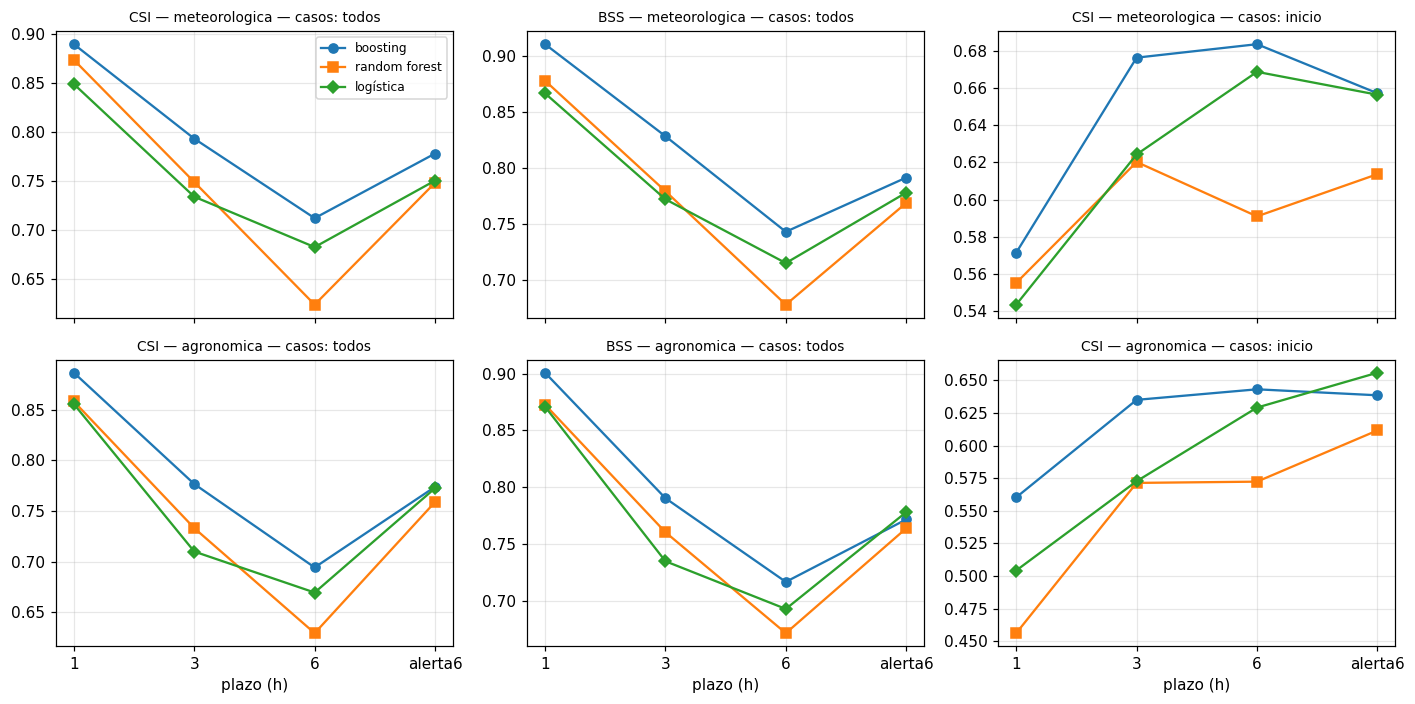

In [8]:
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
orden = [str(l) for l in LEADS_EVAL]
for i, nom_u in enumerate(UMBRALES):
    for j, (k, casos) in enumerate([('CSI', 'todos'), ('BSS', 'todos'), ('CSI', 'inicio')]):
        ax = axs[i, j]
        for m, mk in zip(MODELOS, 'osD'):
            g = MET[(MET.umbral == nom_u) & (MET.casos == casos) & (MET.modelo == m)].set_index('plazo').loc[orden]
            ax.plot(orden, g[k], marker=mk, label=m)
        ax.set_title(f'{k} — {nom_u} — casos: {casos}', fontsize=9)
axs[0, 0].legend(fontsize=8)
for ax in axs[-1]: ax.set_xlabel('plazo (h)')
plt.tight_layout(); plt.show()

### 4.2 Diferencia frente al boosting (bootstrap por noche)

Valores positivos: el modelo es **mejor** que el boosting. Si el intervalo no incluye 0, la diferencia es significativa.

In [9]:
def boot_diff(res, va, vb='boosting', casos='todos'):
    t = res if casos == 'todos' else res[res['inicio']]
    y = t['y'].astype(float)
    cols = {'n': 1.0, 'y': y, 'se_a': (t[f'p_{va}'] - y) ** 2, 'se_b': (t[f'p_{vb}'] - y) ** 2}
    for s, v in (('a', va), ('b', vb)):
        al = t[f'p_{v}'] >= P_ALERTA
        cols[f'h_{s}'], cols[f'f_{s}'], cols[f'm_{s}'] = t['y'] & al, ~t['y'] & al, t['y'] & ~al
    g = pd.DataFrame(cols, index=t.index).astype(float).groupby(t['noche']).sum()
    S = pd.DataFrame(rng.multinomial(len(g), np.ones(len(g)) / len(g), size=N_BOOT) @ g.values, columns=g.columns)
    clim = S['y'] / S['n']; bsc = (S['y'] * (1 - clim) ** 2 + (S['n'] - S['y']) * clim ** 2) / S['n']
    dbss = (S['se_b'] - S['se_a']) / S['n'] / bsc
    dcsi = S['h_a'] / (S['h_a'] + S['f_a'] + S['m_a']) - S['h_b'] / (S['h_b'] + S['f_b'] + S['m_b'])
    return dbss, dcsi

ic = lambda s: f'{s.median():+.3f} [{s.quantile(.025):+.3f}, {s.quantile(.975):+.3f}]'
filas = []
for (nom_u, lead), res in OOF.items():
    for casos in ('todos', 'inicio'):
        for m in ('random forest', 'logística'):
            dbss, dcsi = boot_diff(res, m, casos=casos)
            filas.append({'umbral': nom_u, 'plazo': str(lead), 'casos': casos, 'modelo': m,
                          'ΔBSS': ic(dbss), 'ΔCSI': ic(dcsi),
                          'BSS': 'mejor' if dbss.quantile(.025) > 0 else 'peor' if dbss.quantile(.975) < 0 else 'igual',
                          'CSI': 'mejor' if dcsi.quantile(.025) > 0 else 'peor' if dcsi.quantile(.975) < 0 else 'igual'})
BOOT = pd.DataFrame(filas)
BOOT.to_csv(OUT / 'el_mantaro_comparacion_modelos_bootstrap.csv', index=False)
BOOT[BOOT.casos == 'todos'].pivot_table(index=['umbral', 'plazo'], columns='modelo', values=['ΔCSI', 'ΔBSS'],
                                        aggfunc='first', sort=False)

ΔCSI                                              ΔBSS                         
modelo                           random forest                logística            random forest                logística
umbral        plazo                                                                                                      
meteorologica 1        -0.016 [-0.029, -0.002]  -0.040 [-0.058, -0.024]  -0.033 [-0.040, -0.025]  -0.044 [-0.056, -0.031]
              3        -0.044 [-0.064, -0.024]  -0.059 [-0.083, -0.036]  -0.049 [-0.059, -0.038]  -0.056 [-0.073, -0.040]
              6        -0.088 [-0.115, -0.063]  -0.029 [-0.052, -0.008]  -0.065 [-0.081, -0.050]  -0.028 [-0.045, -0.013]
              alerta6  -0.029 [-0.044, -0.013]  -0.027 [-0.044, -0.012]  -0.022 [-0.036, -0.008]  -0.013 [-0.028, +0.001]
agronomica    1        -0.029 [-0.038, -0.017]  -0.031 [-0.043, -0.021]  -0.028 [-0.034, -0.022]  -0.030 [-0.038, -0.022]
              3        -0.043 [-0.058, -0.029]  -0.066 [-0.082, -0.051]  -0.030 [-0.039, -0.020]  -0.055 [-0.066, -0.044]
              6        -0.065 [-0.084, -0.046]  -0.025 [-0.041, -0.009]  -0.045 [-0.058, -0.032]  -0.024 [-0.036, -0.011]
              alerta6  -0.015 [-0.026, -0.004]  -0.001 [-0.013, +0.010]  -0.007 [-0.019, +0.003]  +0.006 [-0.004, +0.017]

In [10]:
BOOT[BOOT.casos == 'inicio'].pivot_table(index=['umbral', 'plazo'], columns='modelo', values=['ΔCSI', 'ΔBSS'],
                                         aggfunc='first', sort=False)

ΔCSI                                              ΔBSS                         
modelo                           random forest                logística            random forest                logística
umbral        plazo                                                                                                      
meteorologica 1        -0.016 [-0.061, +0.029]  -0.028 [-0.076, +0.022]  -0.030 [-0.062, +0.002]  -0.068 [-0.107, -0.024]
              3        -0.056 [-0.085, -0.027]  -0.052 [-0.085, -0.020]  -0.049 [-0.067, -0.030]  -0.059 [-0.085, -0.035]
              6        -0.092 [-0.124, -0.062]  -0.015 [-0.039, +0.009]  -0.054 [-0.072, -0.036]  -0.009 [-0.026, +0.008]
              alerta6  -0.043 [-0.065, -0.022]  -0.001 [-0.022, +0.021]  -0.014 [-0.036, +0.008]  +0.015 [-0.005, +0.040]
agronomica    1        -0.102 [-0.141, -0.067]  -0.055 [-0.090, -0.022]  -0.051 [-0.074, -0.028]  -0.063 [-0.089, -0.037]
              3        -0.064 [-0.085, -0.039]  -0.062 [-0.086, -0.038]  -0.018 [-0.034, -0.001]  -0.046 [-0.066, -0.028]
              6        -0.071 [-0.091, -0.050]  -0.013 [-0.031, +0.006]  -0.037 [-0.051, -0.022]  -0.009 [-0.024, +0.007]
              alerta6  -0.027 [-0.044, -0.010]  +0.017 [-0.001, +0.035]  +0.000 [-0.018, +0.018]  +0.031 [+0.014, +0.048]

In [11]:
# Resumen: frente al boosting, ¿en cuántas combinaciones (umbral × plazo × casos) es mejor, igual o peor?
pd.concat({k: BOOT.groupby('modelo')[k].value_counts().unstack(fill_value=0) for k in ('BSS', 'CSI')}, axis=1)

BSS              CSI     
              igual mejor peor igual peor
modelo                                   
logística         5     1   10     6   10
random forest     4     0   12     1   15

### 4.3 Calibración

Si un modelo está bien calibrado, cuando dice 30 % la helada ocurre cerca del 30 % de las veces (la diagonal).

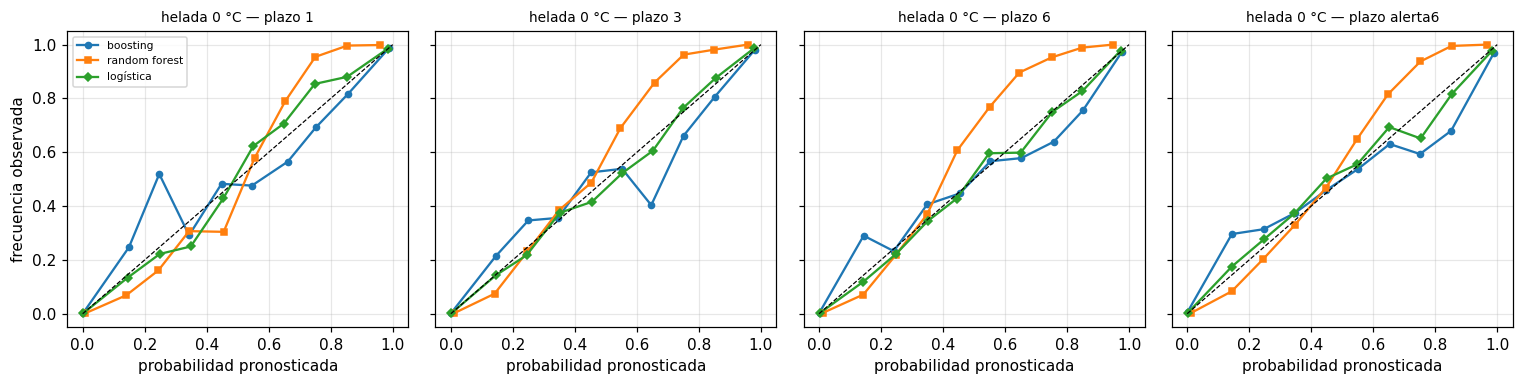

In [12]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
bins = np.linspace(0, 1, 11)
for ax, lead in zip(axs, LEADS_EVAL):
    t = OOF[('meteorologica', lead)]
    for m, mk in zip(MODELOS, 'osD'):
        g = t.groupby(pd.cut(t[f'p_{m}'], bins), observed=True)
        ax.plot(g[f'p_{m}'].mean(), g['y'].mean(), marker=mk, ms=4, label=m)
    ax.plot([0, 1], [0, 1], 'k--', lw=.8); ax.set_title(f'helada 0 °C — plazo {lead}', fontsize=9)
    ax.set_xlabel('probabilidad pronosticada')
axs[0].set_ylabel('frecuencia observada'); axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 5. Tipo de helada: ¿blanca o negra?

Entre las horas de emisión en que **sí habrá helada** en *t+h*, se estima `P(negra | helada)` con la etiqueta del sensor de hoja. Hay pocas heladas negras (24 noches), así que todos los modelos usan **pesos balanceados**. Además de los tres modelos con los 65 predictores, se prueba una **logística simple** con solo tres variables: punto de rocío (Td), depresión T − Td y nubosidad media prevista de las 6 h siguientes.

Se evalúa con **AUC** y **exactitud balanceada**, dejando un año fuera, para el plazo de 3 h y la alerta de 6 h.

In [13]:
REL = linea_base_hoja(D)
noche_s = ALL['noche']
h = D.index.hour
es_noche = (h >= 18) | (h <= 8)
fh = D[es_noche & (D['Tmin'] <= 0)].copy()
fh['senal'] = pd.concat([REL['arriba'], REL['bajo']], axis=1).max(axis=1).reindex(fh.index)
fh['noche'] = noche_s.reindex(fh.index)
fh['dep'] = fh['T'] - fh['Td']
NOCH = fh.groupby('noche').agg(horas_bajo0=('Tmin', 'size'), tmin=('Tmin', 'min'), senal_max=('senal', 'max'),
                               senal_med=('senal', 'median'), dep_med=('dep', 'median'), hr_max=('HR', 'max'),
                               td_min=('Td', 'min'), viento=('viento', 'mean'))
nub_noche = NUB.reindex(D.index[es_noche]).groupby(noche_s.reindex(D.index[es_noche])).mean()
NOCH = NOCH.join(nub_noche)
NOCH['tipo_hoja'] = np.select([NOCH['senal_max'].isna(), NOCH['senal_max'] >= UMB_HIELO], ['sin dato', 'blanca'], 'negra')
# heurística de Td (primer notebook), en la hora de la Tmin
idx_min = fh.groupby('noche')['Tmin'].idxmin()
td_m, dep_m = D.loc[idx_min.values, 'Td'].values, (D['T'] - D['Td']).loc[idx_min.values].values
NOCH['tipo_td'] = np.where((td_m <= 0) & (dep_m <= 3), 'blanca', 'negra')
print(NOCH['tipo_hoja'].value_counts())
pd.crosstab(NOCH['tipo_hoja'], NOCH['tipo_td'], margins=True)

tipo_hoja
blanca    244
negra      24
Name: count, dtype: int64


tipo_td,blanca,negra,All
tipo_hoja,,,
blanca,229,15,244
negra,16,8,24
All,245,23,268


In [14]:
TIPO = NOCH['tipo_hoja'].to_dict()
F_SIMPLE = ['Td', 'dep', 'cloud_cover_med6h']
MODELOS_TIPO = {
    'boosting': (lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                                        min_samples_leaf=20, l2_regularization=2.0,
                                                        class_weight='balanced', random_state=SEED), FEATS),
    'random forest': (lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=10, max_features='sqrt',
                                                     class_weight='balanced_subsample', n_jobs=-1,
                                                     random_state=SEED), FEATS),
    'logística': (lambda: make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(),
                                        LogisticRegression(C=0.1, class_weight='balanced', max_iter=3000)), FEATS),
    'logística simple (3 var.)': (lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                                        LogisticRegression(class_weight='balanced', max_iter=3000)),
                                  F_SIMPLE),
}

OOF_T = {}
for lead in [3, 'alerta6']:
    col = f'y_T_{lead}'
    sub = MUESTRA[MUESTRA[col] <= 0].copy()
    h_obj = sub.index + pd.Timedelta(hours=6 if lead == 'alerta6' else lead)
    sub['noche_obj'] = (h_obj - pd.Timedelta(hours=12)).normalize()
    sub['tipo'] = sub['noche_obj'].map(TIPO)
    sub = sub[sub['tipo'].isin(['blanca', 'negra'])]
    sub['y_negra'] = sub['tipo'] == 'negra'
    for m in MODELOS_TIPO: sub[f'p_{m}'] = np.nan
    for a in ANIOS:
        tr, te = sub['anio'] != a, sub['anio'] == a
        if te.sum() == 0 or sub.loc[tr, 'y_negra'].sum() < 5: continue
        for m, (f, fs) in MODELOS_TIPO.items():
            sub.loc[te, f'p_{m}'] = f().fit(sub.loc[tr, fs], sub.loc[tr, 'y_negra']).predict_proba(sub.loc[te, fs])[:, 1]
    OOF_T[lead] = sub.dropna(subset=[f'p_{m}' for m in MODELOS_TIPO])
    print(f'plazo {lead}: {len(OOF_T[lead])} horas, {int(OOF_T[lead].y_negra.sum())} de helada negra')

plazo 3: 1338 horas, 174 de helada negra


plazo alerta6: 2609 horas, 291 de helada negra


In [15]:
def boot_auc(s, col):
    grupos = [(g['y_negra'].values, g[col].values) for _, g in s.groupby('noche_obj')]
    out = []
    for _ in range(N_BOOT):
        sel = rng.integers(0, len(grupos), len(grupos))
        y = np.concatenate([grupos[i][0] for i in sel]); p = np.concatenate([grupos[i][1] for i in sel])
        if len(np.unique(y)) == 2:
            out.append(roc_auc_score(y, p))
    return np.quantile(out, [.025, .975])

filas = []
for lead, s in OOF_T.items():
    for m in MODELOS_TIPO:
        lo, hi = boot_auc(s, f'p_{m}')
        filas.append({'plazo': str(lead), 'modelo': m, 'AUC': roc_auc_score(s['y_negra'], s[f'p_{m}']),
                      'IC 95 %': f'[{lo:.3f}, {hi:.3f}]',
                      'exactitud balanceada': balanced_accuracy_score(s['y_negra'], s[f'p_{m}'] >= 0.5)})
MET_T = pd.DataFrame(filas)
MET_T.to_csv(OUT / 'el_mantaro_comparacion_modelos_tipo.csv', index=False)
MET_T.round(3)

,plazo,modelo,AUC,IC 95 %,exactitud balanceada
0,3,boosting,0.900,"[0.839, 0.948]",0.716
1,3,random forest,0.896,"[0.844, 0.937]",0.759
2,3,logística,0.879,"[0.811, 0.937]",0.758
3,3,logística simple (3 var.),0.927,"[0.890, 0.958]",0.857
4,alerta6,boosting,0.853,"[0.788, 0.902]",0.646
5,alerta6,random forest,0.854,"[0.797, 0.905]",0.680
6,alerta6,logística,0.802,"[0.725, 0.878]",0.710
7,alerta6,logística simple (3 var.),0.881,"[0.833, 0.921]",0.812


## 6. Calibración de las probabilidades

La calibración corrige las probabilidades de un modelo ya entrenado para que coincidan con la frecuencia observada, sin cambiar el orden de las horas (el AUC no cambia). Se prueban dos métodos de `CalibratedClassifierCV`:

* **isotónica**: una curva escalonada que solo puede subir; flexible, necesita muchos datos;
* **Platt** (`sigmoid`): una curva en forma de S con dos parámetros; más rígida.

**Sin fuga de información.** Dentro de cada año de entrenamiento, la curva se ajusta con una validación interna **por años** (`GroupKFold`): cada parte del modelo se calibra con un año que no vio. El año de prueba sigue sin intervenir en nada.

Se calibran el boosting (con los dos métodos) y el Random Forest (isotónica), que era el peor calibrado. Además del BSS y el CSI se reporta el **ECE** (*expected calibration error*): la distancia media entre la probabilidad pronosticada y la frecuencia observada, en 10 intervalos; 0 es perfecto.

In [16]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GroupKFold

def calibrado(base, metodo):
    def ajustar(X, y, grupos):
        cv = list(GroupKFold(n_splits=grupos.nunique()).split(X, y, grupos))
        return CalibratedClassifierCV(base(), method=metodo, cv=cv).fit(X, y)
    return ajustar

MODELOS_CAL = {'boosting + isotónica': calibrado(boosting, 'isotonic'),
               'boosting + Platt': calibrado(boosting, 'sigmoid'),
               'random forest + isotónica': calibrado(random_forest, 'isotonic')}
TIEMPO_CAL = {m: 0.0 for m in MODELOS_CAL}
for (nom_u, lead), res in OOF.items():
    sub = MUESTRA.loc[res.index]
    for a in ANIOS:
        tr, te = sub['anio'] != a, sub['anio'] == a
        for m, f in MODELOS_CAL.items():
            t0 = time.perf_counter()
            mod = f(sub.loc[tr, FEATS], res.loc[tr, 'y'], sub.loc[tr, 'anio'])
            TIEMPO_CAL[m] += time.perf_counter() - t0
            res.loc[te, f'p_{m}'] = mod.predict_proba(sub.loc[te, FEATS])[:, 1]
    print(f'listo: {nom_u}, plazo {lead}')
pd.Series(TIEMPO_CAL, name='segundos de entrenamiento (total)').round(0)

listo: meteorologica, plazo 1


listo: meteorologica, plazo 3


listo: meteorologica, plazo 6


listo: meteorologica, plazo alerta6


listo: agronomica, plazo 1


listo: agronomica, plazo 3


listo: agronomica, plazo 6


listo: agronomica, plazo alerta6


boosting + isotónica         178.0
boosting + Platt             179.0
random forest + isotónica    148.0
Name: segundos de entrenamiento (total), dtype: float64

In [17]:
def ece(y, p, n_bins=10):
    b = np.clip((p * n_bins).astype(int), 0, n_bins - 1)
    d = pd.DataFrame({'y': y, 'p': p, 'b': b}).groupby('b').agg(y=('y', 'mean'), p=('p', 'mean'), n=('y', 'size'))
    return float((d['n'] * (d['p'] - d['y']).abs()).sum() / d['n'].sum())

CAL = ['boosting', 'boosting + isotónica', 'boosting + Platt', 'random forest', 'random forest + isotónica']
filas = []
for (nom_u, lead), res in OOF.items():
    for casos in ('todos', 'inicio'):
        t = res if casos == 'todos' else res[res['inicio']]
        y = t['y'].values
        bsc = brier_score_loss(y, np.full(len(y), y.mean()))
        for m in CAL:
            p = t[f'p_{m}'].values
            pod, far, c = csi(y, p >= P_ALERTA)
            filas.append({'umbral': nom_u, 'plazo': str(lead), 'casos': casos, 'modelo': m,
                          'BSS': 1 - brier_score_loss(y, p) / bsc, 'CSI': c, 'POD': pod, 'FAR': far,
                          'ECE': ece(y.astype(float), p), 'AUC': roc_auc_score(y, p)})
MET_CAL = pd.DataFrame(filas)
MET_CAL.to_csv(OUT / 'el_mantaro_comparacion_calibracion_metricas.csv', index=False)
MET_CAL[MET_CAL.casos == 'todos'].pivot_table(index=['umbral', 'plazo'], columns='modelo',
                                              values=['BSS', 'CSI', 'ECE'], sort=False)[
    [(k, m) for k in ('BSS', 'CSI', 'ECE') for m in CAL]].round(3)

BSS                                                                                    CSI                                                                                \
modelo                boosting boosting + isotónica boosting + Platt random forest random forest + isotónica boosting boosting + isotónica boosting + Platt random forest random forest + isotónica   
umbral        plazo                                                                                                                                                                                   
meteorologica 1          0.911                0.917            0.917         0.878                     0.888    0.889                0.894            0.894         0.873                     0.867   
              3          0.828                0.828            0.830         0.779                     0.795    0.793                0.791            0.796         0.749                     0.747   
              6          0.743                0.754            0.755         0.678                     0.711    0.712                0.718            0.717         0.623                     0.673   
              alerta6    0.792                0.803            0.803         0.769                     0.780    0.778                0.773            0.781         0.748                     0.743   
agronomica    1          0.901                0.903            0.904         0.873                     0.877    0.887                0.884            0.886         0.858                     0.855   
              3          0.790                0.798            0.798         0.760                     0.772    0.777                0.775            0.772         0.733                     0.747   
              6          0.717                0.735            0.736         0.671                     0.689    0.694                0.699            0.701         0.629                     0.655   
              alerta6    0.772                0.792            0.791         0.764                     0.772    0.774                0.778            0.779         0.759                     0.764   

                           ECE                                                                                
modelo                boosting boosting + isotónica boosting + Platt random forest random forest + isotónica  
umbral        plazo                                                                                           
meteorologica 1          0.002                0.001            0.001         0.008                     0.001  
              3          0.003                0.001            0.002         0.011                     0.002  
              6          0.005                0.002            0.003         0.016                     0.002  
              alerta6    0.011                0.002            0.004         0.017                     0.002  
agronomica    1          0.002                0.001            0.001         0.011                     0.001  
              3          0.007                0.002            0.003         0.019                     0.002  
              6          0.011                0.003            0.005         0.024                     0.001  
              alerta6    0.021                0.004            0.007         0.026                     0.003

In [18]:
MET_CAL[MET_CAL.casos == 'inicio'].pivot_table(index=['umbral', 'plazo'], columns='modelo',
                                               values=['BSS', 'CSI'], sort=False)[
    [(k, m) for k in ('BSS', 'CSI') for m in CAL]].round(3)

BSS                                                                                    CSI                                                                              
modelo                boosting boosting + isotónica boosting + Platt random forest random forest + isotónica boosting boosting + isotónica boosting + Platt random forest random forest + isotónica
umbral        plazo                                                                                                                                                                                
meteorologica 1          0.637                0.655            0.656         0.607                     0.599    0.571                0.583            0.582         0.555                     0.510
              3          0.727                0.726            0.729         0.678                     0.693    0.676                0.668            0.678         0.620                     0.628
              6          0.714                0.726            0.728         0.660                     0.690    0.684                0.690            0.691         0.591                     0.648
              alerta6    0.676                0.697            0.696         0.662                     0.673    0.657                0.650            0.662         0.614                     0.614
agronomica    1          0.595                0.604            0.604         0.544                     0.548    0.560                0.546            0.555         0.456                     0.450
              3          0.649                0.666            0.665         0.631                     0.646    0.635                0.635            0.628         0.571                     0.601
              6          0.666                0.689            0.690         0.629                     0.646    0.643                0.652            0.654         0.572                     0.604
              alerta6    0.645                0.678            0.676         0.645                     0.657    0.639                0.644            0.645         0.612                     0.626

### 6.1 Diferencia frente al boosting sin calibrar (bootstrap por noche)

Positivo: mejor que el boosting actual. *mejor* / *peor* solo si el intervalo al 95 % no incluye 0.

In [19]:
filas = []
for (nom_u, lead), res in OOF.items():
    for casos in ('todos', 'inicio'):
        for m in MODELOS_CAL:
            dbss, dcsi = boot_diff(res, m, casos=casos)
            filas.append({'umbral': nom_u, 'plazo': str(lead), 'casos': casos, 'modelo': m,
                          'ΔBSS': ic(dbss), 'ΔCSI': ic(dcsi),
                          'BSS': 'mejor' if dbss.quantile(.025) > 0 else 'peor' if dbss.quantile(.975) < 0 else 'igual',
                          'CSI': 'mejor' if dcsi.quantile(.025) > 0 else 'peor' if dcsi.quantile(.975) < 0 else 'igual'})
BOOT_CAL = pd.DataFrame(filas)
BOOT_CAL.to_csv(OUT / 'el_mantaro_comparacion_calibracion_bootstrap.csv', index=False)
BOOT_CAL[BOOT_CAL.casos == 'todos'].pivot_table(index=['umbral', 'plazo'], columns='modelo',
                                                values=['ΔBSS', 'ΔCSI'], aggfunc='first', sort=False)

ΔBSS                                                                        ΔCSI                                                   
modelo                    boosting + isotónica         boosting + Platt random forest + isotónica     boosting + isotónica         boosting + Platt random forest + isotónica
umbral        plazo                                                                                                                                                          
meteorologica 1        +0.006 [+0.002, +0.011]  +0.007 [+0.003, +0.010]   -0.022 [-0.031, -0.014]  +0.004 [-0.004, +0.012]  +0.005 [-0.003, +0.013]   -0.023 [-0.037, -0.008]
              3        +0.000 [-0.006, +0.006]  +0.002 [-0.005, +0.008]   -0.034 [-0.046, -0.023]  -0.002 [-0.016, +0.011]  +0.002 [-0.011, +0.016]   -0.046 [-0.065, -0.026]
              6        +0.011 [+0.002, +0.020]  +0.012 [+0.005, +0.019]   -0.033 [-0.049, -0.017]  +0.007 [-0.006, +0.019]  +0.005 [-0.007, +0.017]   -0.039 [-0.063, -0.019]
              alerta6  +0.011 [+0.003, +0.019]  +0.011 [+0.005, +0.019]   -0.012 [-0.025, +0.000]  -0.005 [-0.014, +0.005]  +0.003 [-0.006, +0.012]   -0.034 [-0.050, -0.019]
agronomica    1        +0.002 [-0.000, +0.005]  +0.003 [+0.000, +0.006]   -0.023 [-0.029, -0.017]  -0.003 [-0.009, +0.004]  -0.001 [-0.007, +0.006]   -0.032 [-0.041, -0.021]
              3        +0.008 [+0.002, +0.012]  +0.008 [+0.004, +0.012]   -0.018 [-0.027, -0.008]  -0.002 [-0.010, +0.006]  -0.005 [-0.013, +0.004]   -0.031 [-0.043, -0.017]
              6        +0.019 [+0.012, +0.025]  +0.020 [+0.014, +0.025]   -0.028 [-0.040, -0.015]  +0.005 [-0.005, +0.014]  +0.006 [-0.003, +0.015]   -0.040 [-0.055, -0.024]
              alerta6  +0.020 [+0.014, +0.026]  +0.019 [+0.014, +0.025]   +0.001 [-0.010, +0.012]  +0.004 [-0.002, +0.010]  +0.005 [-0.001, +0.011]   -0.009 [-0.021, +0.002]

In [20]:
# Resumen sobre las 16 combinaciones (umbral × plazo × casos)
pd.concat({k: BOOT_CAL.groupby('modelo')[k].value_counts().unstack(fill_value=0) for k in ('BSS', 'CSI')}, axis=1)

BSS              CSI           
BSS                       igual mejor peor igual mejor peor
modelo                                                     
boosting + Platt              3    13    0    15     1    0
boosting + isotónica          4    12    0    16     0    0
random forest + isotónica     5     0   11     2     0   14

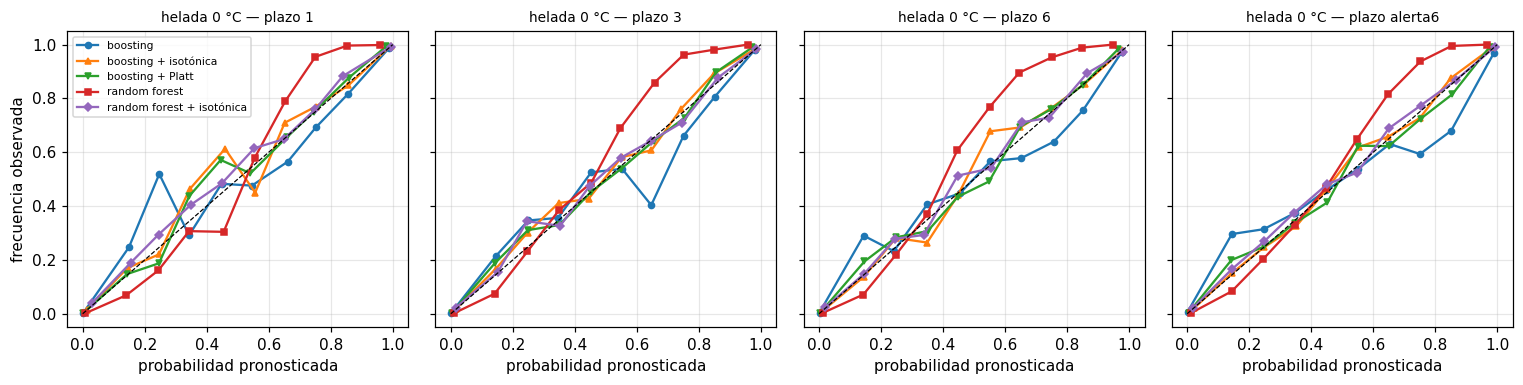

In [21]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
bins = np.linspace(0, 1, 11)
for ax, lead in zip(axs, LEADS_EVAL):
    t = OOF[('meteorologica', lead)]
    for m, mk in zip(CAL, 'o^vsD'):
        g = t.groupby(pd.cut(t[f'p_{m}'], bins), observed=True)
        ax.plot(g[f'p_{m}'].mean(), g['y'].mean(), marker=mk, ms=4, label=m)
    ax.plot([0, 1], [0, 1], 'k--', lw=.8); ax.set_title(f'helada 0 °C — plazo {lead}', fontsize=9)
    ax.set_xlabel('probabilidad pronosticada')
axs[0].set_ylabel('frecuencia observada'); axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 7. Conclusiones

**Probabilidad de helada: el boosting gana.**

* Tiene el mayor CSI y BSS en casi todas las combinaciones. Frente a él, en las 16 combinaciones de umbral × plazo × casos:
  * **Random Forest** es significativamente **peor en CSI en 15** y en BSS en 12, y nunca mejor. Su mayor desventaja está a 6 h: CSI 0.62 frente a 0.71 (helada 0 °C, todos los casos).
  * **Logística** es peor en CSI en 10 e igual en 6; en BSS es peor en 10, igual en 5 y mejor en 1 (alerta 6 h agronómica, casos de inicio).
* La logística queda cerca del boosting a 6 h y en la alerta de 6 h, sobre todo en los casos de inicio; a 1–3 h el boosting le saca entre 0.03 y 0.07 de CSI.
* El AUC es casi idéntico en los tres modelos (0.98–0.999): todos ordenan bien las horas; la diferencia está en **qué tan buenas son las probabilidades** (BSS) y en **acertar con el umbral de 0.5** (CSI).
* **Calibración.** La logística es la mejor calibrada. El Random Forest da probabilidades demasiado bajas en el rango medio (cuando dice 50–60 %, en los plazos de 3 y 6 h hiela entre el 70 y el 90 % de las veces), por eso pierde heladas con el umbral 0.5. El boosting es algo irregular entre 0.2 y 0.8, pero sin un sesgo claro.
* **Costo.** El boosting y el Random Forest tardan parecido (≈ 1 min para toda la validación); la logística, unos 10 s.

**Tipo de helada: la logística simple con 3 variables es la mejor.**

* Con solo Td, T − Td y la nubosidad media prevista de 6 h, la logística simple da **AUC 0.93 a 3 h y 0.88 en la alerta de 6 h**, frente a 0.90 y 0.85 del boosting con 65 variables, y una exactitud balanceada mucho mayor (0.86 frente a 0.72 a 3 h).
* Los intervalos de confianza se solapan, así que no es una diferencia demostrada, pero el modelo simple **no es peor** y es mucho más fácil de explicar y de mantener.
* Es coherente con la importancia de variables del notebook de nubosidad: el tipo de helada depende sobre todo de lo seco que está el aire. Con 24 noches negras, un modelo con muchos predictores sobreajusta.

**Calibración: mejora las probabilidades del boosting, no sus alertas.**

* Con la calibración **isotónica o de Platt**, el BSS del boosting mejora de forma significativa en 12–13 de las 16 combinaciones y **nunca empeora**. La mejora es pequeña a 1–3 h (+0.000 a +0.008) y mayor a 6 h y en la alerta de 6 h (+0.011 a +0.020).
* El error de calibración (ECE) baja a la mitad o menos: en la alerta de 6 h, de 0.011 a 0.002 (0 °C) y de 0.021 a 0.004 (2 °C). En el gráfico, las curvas calibradas quedan casi sobre la diagonal; el boosting sin calibrar **exageraba** el riesgo entre 0.6 y 0.9 (a 6 h, cuando decía 75 % helaba cerca del 64 %) y lo **subestimaba** por debajo de 0.2.
* El **CSI no cambia** de forma significativa (15–16 combinaciones iguales): las horas cerca del umbral de 0.5 son pocas, y la calibración mueve sobre todo probabilidades intermedias.
* Isotónica y Platt dan resultados casi idénticos. Platt es más simple (2 parámetros) y algo más estable.
* El **Random Forest calibrado** queda bien calibrado (ECE ≤ 0.003), pero sigue siendo peor que el boosting: peor en CSI en 14 combinaciones y en BSS en 11. Su problema no era solo la calibración.
* **Costo:** entrenar con calibración tarda unas 3 veces más (≈ 3 min frente a 1 min para toda la validación), porque cada modelo se entrena una vez por año interno.

**Recomendación.**

1. Mantener el **boosting** para la probabilidad de helada (0 °C y 2 °C), **calibrado con Platt**: probabilidades más fiables, sobre todo a 4–6 h, sin perder nada en las alertas.
2. Considerar **reemplazar el modelo de tipo** por la logística simple de 3 variables, o al menos usarla como referencia, y revisarlo cuando haya más temporadas con heladas negras.
3. Descartar el Random Forest: ni calibrado alcanza al boosting.

*Advertencia:* los hiperparámetros de los modelos se fijaron a mano, con valores habituales; un ajuste sistemático podría acortar algo las diferencias, sobre todo para el Random Forest.
